# Khai báo thư viện, đọc dữ liệu và tiền xử lý One-Hot Encoding

In [ ]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

import time
import pandas as pd
import matplotlib.pyplot as plt
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth

# Đọc tập dữ liệu Groceries Dataset (bỏ qua dòng lỗi định dạng)
df = pd.read_csv('groceries.csv', on_bad_lines='skip')

# Xử lý làm sạch và gom nhóm các mặt hàng theo từng giao dịch
if 'itemDescription' in df.columns:
    # Loại bỏ các dòng thiếu itemDescription và ép kiểu về chuỗi
    df = df.dropna(subset=['itemDescription'])
    df['itemDescription'] = df['itemDescription'].astype(str)
    transactions = df.groupby(['Member_number', 'Date'])['itemDescription'].apply(list).tolist()
else:
    transactions = df.dropna().values.tolist()

# Lọc sạch các phần tử rỗng hoặc không hợp lệ trong từng giao dịch
transactions = [[str(item).strip() for item in trans if pd.notna(item) and str(item).strip() != ''] for trans in transactions]

# Chuyển đổi dữ liệu về dạng One-Hot Encoding
te = TransactionEncoder()
te_ary = te.fit(transactions).transform(transactions)
df_encoded = pd.DataFrame(te_ary, columns=te.columns_)

print(f"Đã đọc và mã hóa thành công! Kích thước bảng dữ liệu: {df_encoded.shape}")

# Khai báo sẵn danh sách mức min_sup cho các phần tiếp theo
min_sups = [0.0001, 0.0003, 0.0005, 0.0008, 0.001]
min_sup_labels = ['0.01%', '0.03%', '0.05%', '0.08%', '0.1%']

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------
Đã đọc và mã hóa thành công! Kích thước bảng dữ liệu: (1004, 155)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

# a. Tìm tất cả các tập phổ biến bằng thuật toán Apriori

In [ ]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

# Sử dụng TransactionEncoder để chuyển đổi danh sách giao dịch sang ma trận one-hot
te = TransactionEncoder()
te_ary = te.fit(transactions).transform(transactions)
df_encoded = pd.DataFrame(te_ary, columns=te.columns_)

print(f"Kích thước bảng dữ liệu sau khi One-Hot Encoding: {df_encoded.shape}")
display(df_encoded.head())

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------
Kích thước bảng dữ liệu sau khi One-Hot Encoding: (1004, 155)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Instant food products,UHT-milk,abrasive cleaner,artif. sweetener,baby cosmetics,baking powder,bathroom cleaner,beef,berries,beverages,...,tropical fruit,turkey,vinegar,waffles,whipped/sour cream,white bread,white wine,whole milk,yogurt,zwieback
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,True,...,False,False,False,False,False,False,False,False,True,False


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

# b. Tìm tất cả các tập phổ biến bằng thuật toán FP-Growth

In [6]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

import time
import pandas as pd
import warnings
warnings.filterwarnings('ignore')
from mlxtend.frequent_patterns import fpgrowth

# Tạo danh sách chứa kết quả tổng hợp
results_data = []

print("--- THỰC NGHIỆM VỚI THUẬT TOÁN FP-GROWTH ---")
for sup, label in zip(min_sups, min_sup_labels):
    start_time = time.time()
    res_fp = fpgrowth(df_encoded, min_support=sup, use_colnames=True)
    end_time = time.time()

    fp_time = end_time - start_time

    # Thêm dữ liệu vào danh sách
    results_data.append({
        'min_sup': label,
        'Số lượng tập phổ biến': len(res_fp),
        'Thời gian (giây)': round(fp_time, 4)
    })

# Chuyển thành DataFrame để hiển thị dạng bảng
df_summary = pd.DataFrame(results_data)
display(df_summary)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------
--- THỰC NGHIỆM VỚI THUẬT TOÁN FP-GROWTH ---


,min_sup,Số lượng tập phổ biến,Thời gian (giây)
0,0.01%,7052,21.3236
1,0.03%,7052,29.9309
2,0.05%,7052,21.9009
3,0.08%,7052,19.0368
4,0.1%,1553,3.7253


# c. Vẽ biểu đồ so sánh thời gian xử lý giữa hai thuật toán

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------


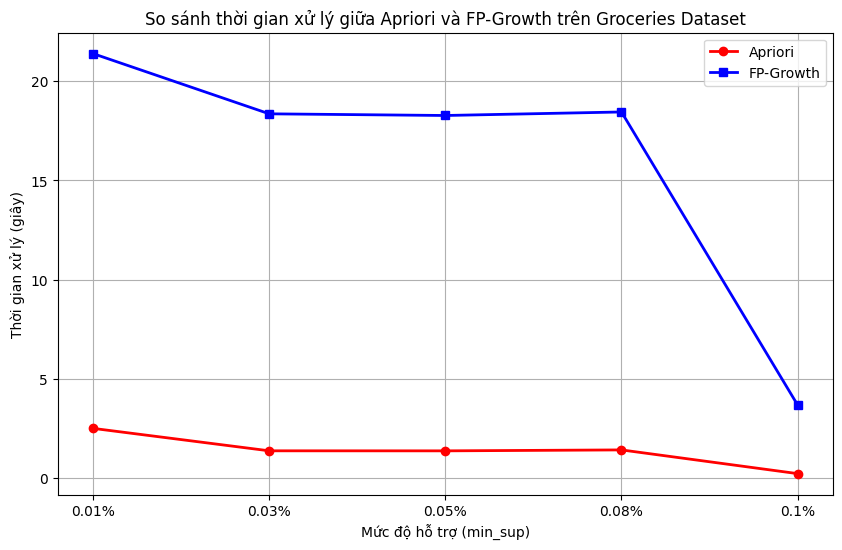

In [9]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

import time
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from mlxtend.frequent_patterns import apriori, fpgrowth

# 1. Chạy lại nhanh thực nghiệm để lưu các mảng thời gian
apriori_times = []
fpgrowth_times = []

for sup in min_sups:
    # Apriori
    start_t = time.time()
    res_ap = apriori(df_encoded, min_support=sup, use_colnames=True)
    apriori_times.append(time.time() - start_t)

    # FP-Growth
    start_t = time.time()
    res_fp = fpgrowth(df_encoded, min_support=sup, use_colnames=True)
    fpgrowth_times.append(time.time() - start_t)

# 2. Vẽ biểu đồ so sánh (Phần c)
plt.figure(figsize=(10, 6))
plt.plot(min_sup_labels, apriori_times, marker='o', label='Apriori', color='red', linewidth=2)
plt.plot(min_sup_labels, fpgrowth_times, marker='s', label='FP-Growth', color='blue', linewidth=2)

plt.title('So sánh thời gian xử lý giữa Apriori và FP-Growth trên Groceries Dataset')
plt.xlabel('Mức độ hỗ trợ (min_sup)')
plt.ylabel('Thời gian xử lý (giây)')
plt.legend()
plt.grid(True)
plt.show()